# 01b Preprocess the indicator: detections on the routes towards Switzerland

Our main models forecast Swiss asylum applications from the past of the series itself. But many people who apply for asylum in Switzerland first cross the external borders of Europe, so movements on the migration routes could announce changes in Swiss applications before they happen. In the present notebook, we prepare such an **indicator**: the detections of illegal border-crossings published by Frontex, the EU's border agency.

We load and check the Frontex data and build **one indicator series**, the detections on the three routes towards Switzerland. We then work out what is really known at our forecast cutoff, because an indicator is only useful if it is published in time. Finally, we explore it next to the target before the test period and save a clean file for `02c_estimate_indicator.ipynb`, where we test whether it improves the forecasts.

We read the Frontex file `../data/raw/frontex_detections_by_route_monthly.csv` (described in `../data/raw/SOURCES.md`) and the clean target from `01_preprocess.ipynb` (`../data/processed/asylum_clean.csv`). We save the clean indicator as `../data/processed/routes_clean.csv`, and one figure in `../output/figures/`.

The notebook must be run with `code/` as the working directory, as explained in the README, because all file paths start from there.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the raw data

Frontex publishes the number of **detections of illegal border-crossings** at the external borders of the EU and the Schengen countries, every month, by route. The published file has one row per route and nationality; we aggregated it to one column per route, because we need movements on the routes, not by nationality. `SOURCES.md` explains how we did this and gives the totals we checked.

We have to be careful with the meaning of these numbers. Frontex counts *detections*, not persons: the same person can be detected several times, for example once on the Eastern Mediterranean route and again on the Western Balkan route. So the numbers are an indicator of movement towards Europe, not a count of people, and we use them only as a signal for our forecasts.

In [2]:
routes = pd.read_csv("../data/raw/frontex_detections_by_route_monthly.csv")
routes["month"] = pd.to_datetime(routes["month"], format="%Y-%m")
routes = routes.set_index("month")

print("Number of months:", routes.shape[0])
print("First month:", routes.index[0])
print("Last month: ", routes.index[-1])
routes.head()

Number of months: 213
First month: 2009-01-01 00:00:00
Last month:  2026-09-01 00:00:00


,eastern_mediterranean,central_mediterranean,western_mediterranean,western_african,western_balkan,eastern_borders,circular_route_from_albania_to_greece,black_sea,other
month,,,,,,,,,
2009-01-01,2730,1491,508,361,177,93,1521,0,0
2009-02-01,2228,1221,302,685,327,82,1884,1,0
2009-03-01,2870,2519,656,392,355,133,2368,0,1
2009-04-01,3298,1981,423,0,161,112,4207,0,0
2009-05-01,3750,610,557,0,214,115,5512,0,0


## 2. Check the data

We run the same checks as in `01_preprocess.ipynb`, for the same reasons: missing values would leave holes in the features, missing months would shift the series, and values of zero would break the logarithm we want to take later (the logarithm of 0 does not exist).

In [3]:
first, last = routes.index[0], routes.index[-1]
n_expected = 12 * (last.year - first.year) + (last.month - first.month) + 1
print("Expected number of months:", n_expected, "| in the data:", routes.shape[0])
print("Missing values:", routes.isna().sum().sum())
print()
print("Number of months with zero detections, per route:")
print((routes == 0).sum())

Expected number of months: 213 | in the data: 213
Missing values: 0

Number of months with zero detections, per route:
eastern_mediterranean                      0
central_mediterranean                      1
western_mediterranean                      0
western_african                           29
western_balkan                             0
eastern_borders                            0
circular_route_from_albania_to_greece      0
black_sea                                182
other                                    179
dtype: int64


As we can see, the file has 213 months, from January 2009 to September 2026, with no missing value and no missing month. Some routes have months with zero detections: the Central Mediterranean once, the Western African route 29 times, and the two small routes (Black Sea, Other) in most months. The three routes we will use, apart from the single zero on the Central Mediterranean, never have a month with zero detections.

So the data are complete. The zeros only matter for single routes, so we will build our indicator in a way that avoids them.

## 3. One indicator: the three routes towards Switzerland

We decided **before looking at any relationship with Swiss applications** to use one indicator series: the sum of detections on the three routes that lead towards Switzerland. Fixing the choice in advance matters: if we picked the routes that happen to move most with Swiss applications, the indicator would look better in our data than it really is.

The three routes are the **Central Mediterranean** (sea arrivals in Italy and Malta, Italy being Switzerland's southern neighbour), the **Eastern Mediterranean** (arrivals in Greece and Cyprus) and the **Western Balkan** route (the land route through the Balkans towards Austria).

We use one series and not three, because we have relatively few months, so we keep the number of features small, as the feedback on our project plan recommended: every extra feature is one more number the model has to estimate from the same data. The sum has another advantage: unlike the Central Mediterranean route alone, it has no month with zero detections.

In [4]:
three_routes = ["central_mediterranean", "eastern_mediterranean", "western_balkan"]
routes["routes_to_switzerland"] = routes[three_routes].sum(axis=1)

print("Smallest monthly value of the sum:", routes["routes_to_switzerland"].min())
print("Share of all detections on all routes (2009-01 to 2026-09):",
      round(routes["routes_to_switzerland"].sum() / routes.drop(columns="routes_to_switzerland").sum().sum(), 3))

Smallest monthly value of the sum: 952
Share of all detections on all routes (2009-01 to 2026-09): 0.871


The output shows that the sum of the three routes is never below 952 detections a month, so its logarithm always exists. Together, the three routes hold 87% of all detections in the file.

This means that our indicator covers most of the movement towards Europe, and we can take its logarithm. The next question is whether it is known in time.

## 4. What is known at the cutoff?

An indicator can only help a forecast if it is already published when the forecast is made. So we must check its publication delay carefully, otherwise our backtest would use information that a planner did not yet have, and look better than it could be in practice.

The file we downloaded on 17 November 2026 is dated **4 November 2026**, and its last month is **September 2026**. So, around the 15th of month $m$ (our cutoff), Frontex is known up to month $m-2$, one month less than our target, which is known up to $m-1$:

| At the cutoff (around the 15th of month $m$) | Last month known |
|---|---|
| Asylum applications in Switzerland (target) | $m-1$ = the forecast origin $t$ |
| Detections on the routes (Frontex file) | $m-2$ = $t-1$ |

We assume that Frontex published with the same delay in the past. This gives the rule for `02c_estimate_indicator.ipynb`: at a forecast origin $t$, a model may use the detections up to month $t-1$ only.

Like our target, the Frontex numbers are revised later ("Frontex regularly publishes updates", say the notes of the file). We use today's values, not the values first published each month; this is a limitation we report.

In [5]:
print("Last month in the Frontex file:", routes.index[-1], "(file dated 4 November 2026)")

Last month in the Frontex file: 2026-09-01 00:00:00 (file dated 4 November 2026)


## 5. Explore the indicator next to the target, before the test period

To see how the indicator relates to Swiss applications, we join it to the target by month with `merge`. We keep only the months before the test period, as in `01_preprocess.ipynb`, so that nothing we learn here comes from the test months.

In [6]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])

both = pd.merge(clean, routes[["routes_to_switzerland"]].reset_index(), on="month", how="inner")
both = both[both["period"] != "test"].set_index("month")
both["log_routes"] = np.log(both["routes_to_switzerland"])

print("Months with both series, before the test period:", both.shape[0])
print("From", both.index[0], "to", both.index[-1])

Months with both series, before the test period: 189
From 2009-01-01 00:00:00 to 2024-09-01 00:00:00


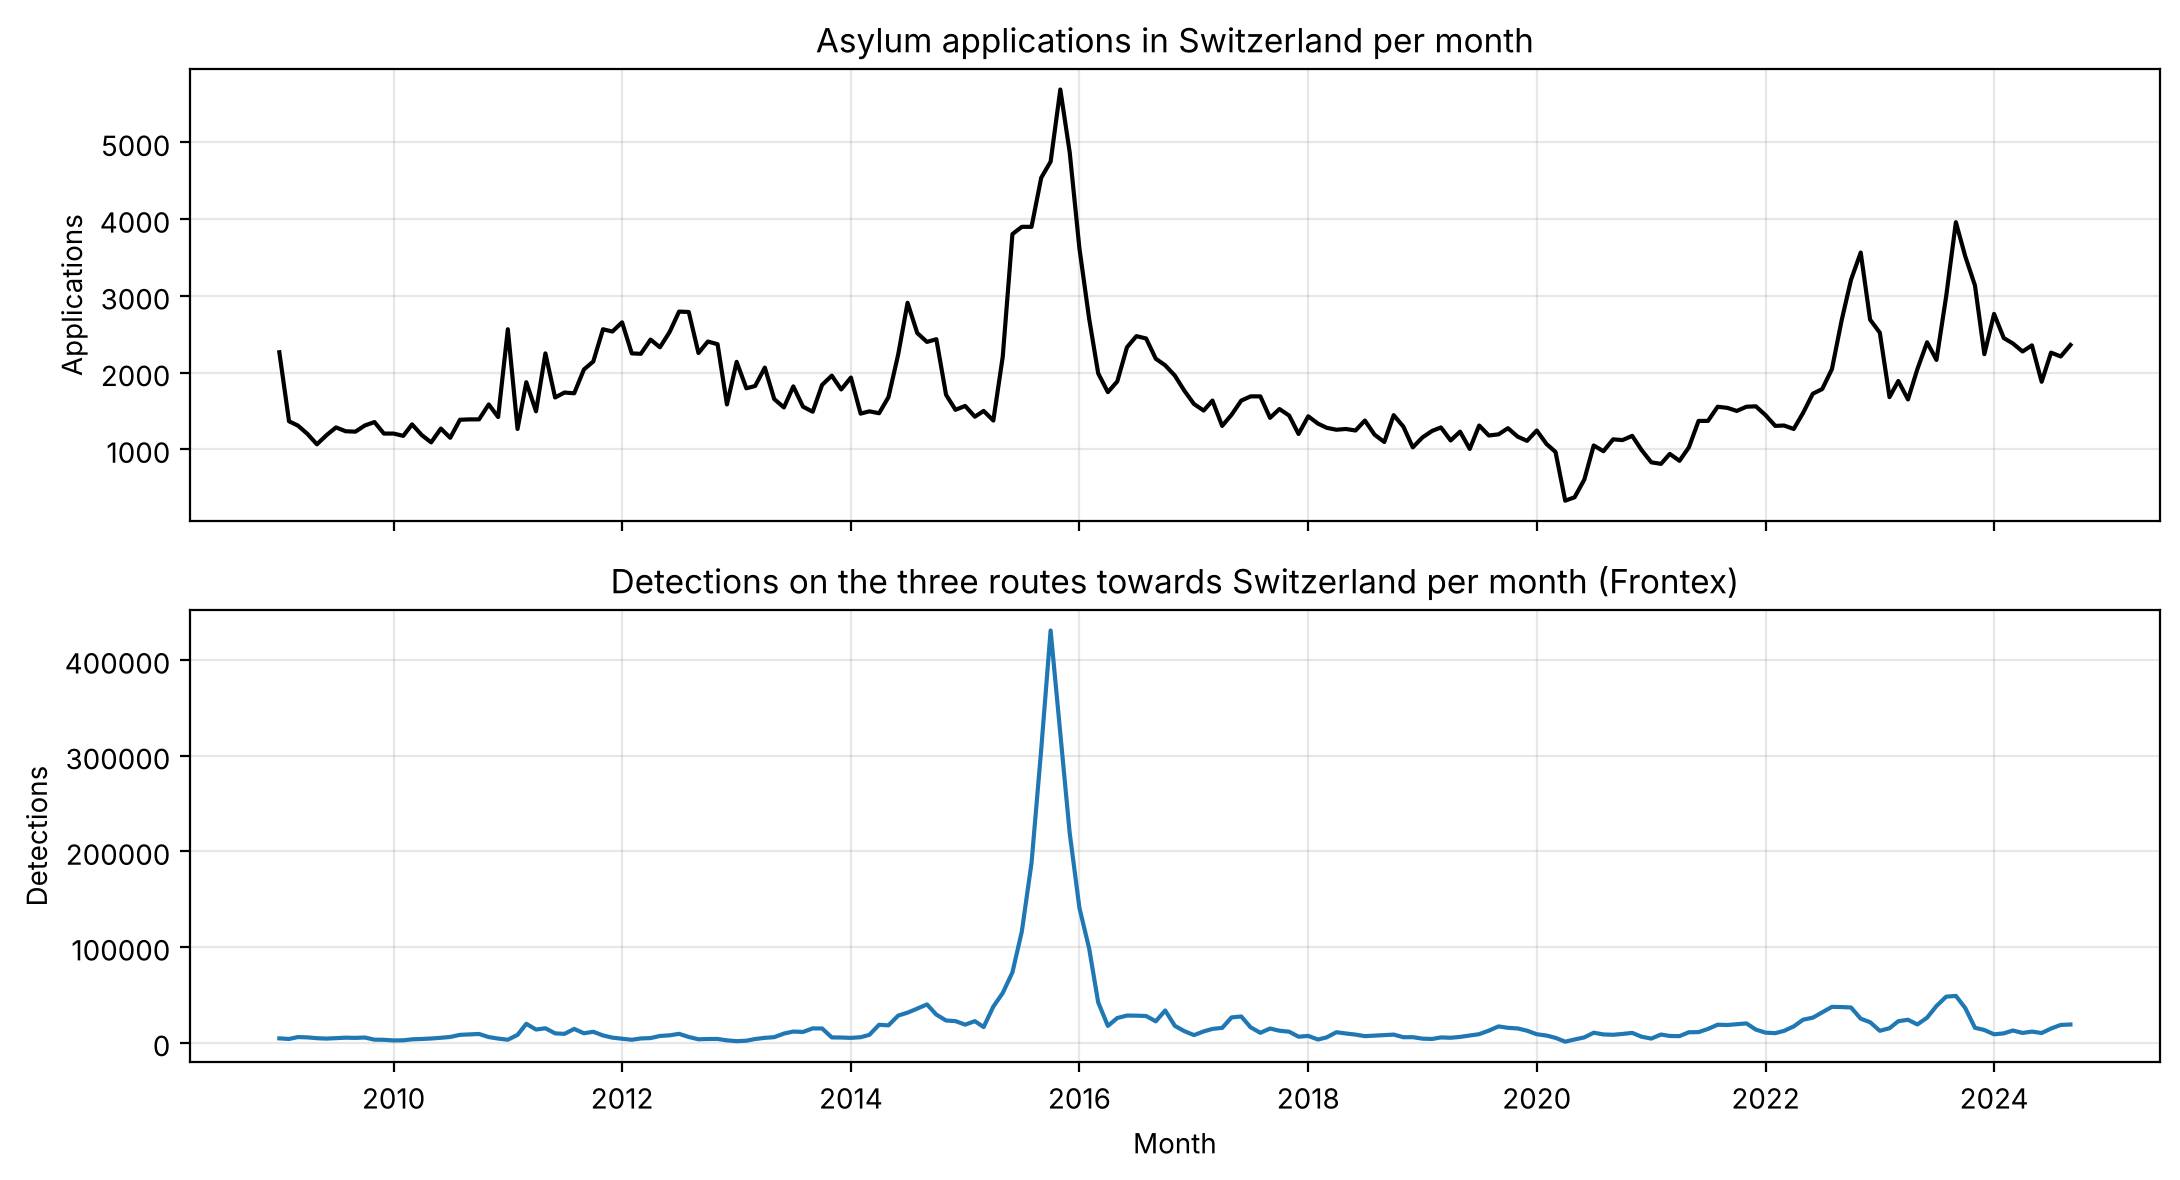

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(both.index, both["applicants_total"], color="black")
axes[0].set_title("Asylum applications in Switzerland per month")
axes[0].set_ylabel("Applications")
axes[1].plot(both.index, both["routes_to_switzerland"], color="tab:blue")
axes[1].set_title("Detections on the three routes towards Switzerland per month (Frontex)")
axes[1].set_ylabel("Detections")
axes[1].set_xlabel("Month")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01b_routes_and_applications.png")
plt.show()

In [8]:
# The highest months of the indicator (sort_values)
print(both["routes_to_switzerland"].sort_values(ascending=False).head(3))

month
2015-10-01    430879
2015-11-01    322656
2015-09-01    306699
Name: routes_to_switzerland, dtype: int64


In the plot, the indicator is dominated by one huge peak: the three highest months are September to November 2015, with a maximum of 430,879 detections in October 2015, at about the same time as the highest months of applications in Switzerland (upper panel). Smaller rises appear on both panels in 2022 and 2023.

So the two series clearly move together in the big events. Because the 2015 peak is so large, we work with the logarithm of the detections, as for the target, so that one extreme month does not dominate. The key question is whether the routes move *before* Switzerland, which we look at next.

### Do changes on the routes come before changes in Switzerland?

For a forecast, it is not enough that the two series move together: the routes must move **first**. To check this, we compare **monthly changes** of the logs, not the levels. Two series that both trend up or down over the years can look strongly correlated without any real link (a spurious correlation); looking at monthly changes removes this. We compute the correlation between the change of applications in month $s$ and the change of detections $k$ months earlier, for $k = 0, \dots, 6$, with `np.corrcoef`.

This table is a **description**, not a choice. The lag the indicator gets in `02c_estimate_indicator.ipynb` is fixed by what is known at the cutoff (section 4), not by which lag looks best here; otherwise we would fit the indicator to our data.

In [9]:
d_apps = np.diff(both["log_applicants"].to_numpy())     # change of log applications, month by month
d_routes = np.diff(both["log_routes"].to_numpy())        # change of log detections, month by month

def lagged_corr(k):
    # Correlation between the change of applications in month s and the change of detections in month s - k
    if k == 0:
        return np.corrcoef(d_apps, d_routes)[0, 1]
    return np.corrcoef(d_apps[k:], d_routes[:-k])[0, 1]

lag_table = pd.DataFrame({"correlation": [round(lagged_corr(k), 2) for k in range(7)]},
                         index=pd.Index(range(7), name="detections k months earlier"))
lag_table

,correlation
detections k months earlier,
0,0.31
1,0.35
2,0.08
3,0.07
4,-0.02
5,-0.08
6,-0.12


The correlations show that the change of applications in Switzerland is correlated with the change of detections in the same month (0.31) and one month earlier (0.35). With detections two or more months earlier, the correlation is close to zero (0.08 at $k = 2$, 0.07 at $k = 3$, and between −0.12 and −0.02 for $k = 4$ to $6$).

This means that movements on the routes show up in Switzerland almost at once, within about a month. But at the cutoff, the newest detection month we know is $t-1$, while the first month we forecast is $t+1$: the gap is at least two months, exactly where the correlation is close to zero. So we expect the indicator to add **little** to our forecasts. We still test it in `02c_estimate_indicator.ipynb`, as planned, because only the backtest can tell for sure. If it does not help, that is an honest result in itself: the information arrives too late for SEM's decision.

## 6. Save the clean indicator

We keep the month, the three routes, their sum and its logarithm. The logarithm is computed for all months, but it transforms each value on its own, so nothing is learned from other months and nothing leaks from the test period.

In [10]:
routes["log_routes"] = np.log(routes["routes_to_switzerland"])
routes_clean = routes[three_routes + ["routes_to_switzerland", "log_routes"]].reset_index()
routes_clean.to_csv("../data/processed/routes_clean.csv", index=False)
print("Saved", routes_clean.shape[0], "months and the columns", list(routes_clean.columns))

Saved 213 months and the columns ['month', 'central_mediterranean', 'eastern_mediterranean', 'western_balkan', 'routes_to_switzerland', 'log_routes']


## Summary

The Frontex file is complete: it has 213 months, from January 2009 to September 2026, without missing values or gaps. The three routes towards Switzerland (Central Mediterranean, Eastern Mediterranean, Western Balkan) hold 87% of all detections.

We use one indicator, the sum of these three routes, in logs. We chose it before looking at the target, so that the choice cannot be fitted to the data, and using a single series keeps the number of features small.

The indicator has one drawback: it is published one month later than the target. At the cutoff, Frontex is known up to month $m-2$, so at a forecast origin $t$ the newest indicator month is $t-1$.

A first look shows that the signal comes early, but not early enough. Changes on the routes go together with changes in Switzerland in the same month and one month later, but not two or more months later, which is exactly the gap we face at the cutoff. We test the indicator anyway in `02c_estimate_indicator.ipynb`, which reads `../data/processed/routes_clean.csv`.